Cilj: Klasifikacija asteroida blizu Zemlje na potencijalno opasne i neopasne na osnovu veličine, brzine i udaljenosti.
Izvor podataka: NASA NeoWs API (prikupljeno 150 zapisa kroz više sedmodnevnih upita).

Glavni zaključci: Skup podataka je nebalansiran (manje opasnih nego neopasnih), pa je važno pratiti recall i matricu zabune, a ne samo ukupnu tačnost.

Sledeći koraci: Proširiti uzorak na duži vremenski period, testirati još modela i podesiti prag odlučivanja.

In [7]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Sve biblioteke su uspešno učitane!")

Sve biblioteke su uspešno učitane!


In [8]:
from datetime import datetime, timedelta
import time

api_key = "DEMO_KEY"
base_url = "https://api.nasa.gov/neo/rest/v1/feed"

# Počinjemo pre 28 dana i idemo u blokovima od po 7 dana
start_date = datetime.today() - timedelta(days=28)
all_asteroids = []

for i in range(4):  # 4 puta po 7 dana = 28 dana
  chunk_start = (start_date + timedelta(days=i * 7)).strftime("%Y-%m-%d")
  chunk_end = (start_date + timedelta(days=(i + 1) * 7 - 1)).strftime(
      "%Y-%m-%d")

  params = {
      "start_date": chunk_start,
      "end_date": chunk_end,
      "api_key": api_key,
  }

  response = requests.get(base_url, params=params)

  if response.status_code == 200:
    data = response.json()
    near_earth_objects = data["near_earth_objects"]

    # Podaci su grupisani po datumima, pa prolazimo kroz svaki dan
    for date_str, asteroids_on_day in near_earth_objects.items():
      for ast in asteroids_on_day:
        # Uzimamo prvi podatak o približavanju Zemlji
        approach = ast["close_approach_data"][0]

        all_asteroids.append({
            "id": ast["id"],
            "name": ast["name"],
            "min_diameter_km": ast["estimated_diameter"]["kilometers"][
                "estimated_diameter_min"
            ],
            "max_diameter_km": ast["estimated_diameter"]["kilometers"][
                "estimated_diameter_max"
            ],
            "velocity_km_h": float(
                approach["relative_velocity"]["kilometers_per_hour"]
            ),
            "miss_distance_km": float(approach["miss_distance"]["kilometers"]),
            "is_hazardous": ast["is_potentially_hazardous_asteroid"],
        })

    print(f"Učitan period: {chunk_start} do {chunk_end}")
  else:
    print(f"Greška za {chunk_start}: status {response.status_code}")

  time.sleep(1)  # kratka pauza da ne preopteretimo API

df = pd.DataFrame(all_asteroids)
print("\nUkupno pronađenih asteroida:", len(df))
df.head()

Učitan period: 2026-10-30 do 2026-11-05
Učitan period: 2026-11-06 do 2026-11-12
Greška za 2026-11-13: status 429
Greška za 2026-11-20: status 429

Ukupno pronađenih asteroida: 82


,id,name,min_diameter_km,max_diameter_km,velocity_km_h,miss_distance_km,is_hazardous
0,2307493,307493 (2002 XP90),0.513517,1.148259,57938.912815,4.586564e+07,False
1,3255980,(2004 TP1),0.192555,0.430566,45617.259781,9.300135e+06,True
2,3720918,(2015 LJ),0.030518,0.068240,16636.546566,4.567339e+07,False
3,2612856,612856 (2004 TP1),0.188172,0.420765,45617.309021,9.300214e+06,True
4,3311964,(2006 AM4),0.111829,0.250058,87613.380642,1.901299e+07,True


Tipovi podataka i broj ne-praznih vrednosti:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 82 entries, 0 to 81
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                82 non-null     object 
 1   name              82 non-null     object 
 2   min_diameter_km   82 non-null     float64
 3   max_diameter_km   82 non-null     float64
 4   velocity_km_h     82 non-null     float64
 5   miss_distance_km  82 non-null     float64
 6   is_hazardous      82 non-null     bool   
dtypes: bool(1), float64(4), object(2)
memory usage: 4.1+ KB
None

Broj praznih (NaN) vrednosti po kolonama:
id                  0
name                0
min_diameter_km     0
max_diameter_km     0
velocity_km_h       0
miss_distance_km    0
is_hazardous        0
dtype: int64

Distribucija klasa (is_hazardous):
is_hazardous
False    67
True     15
Name: count, dtype: int64

Procenat po klasama:
is_hazardous
False    81.707317
T

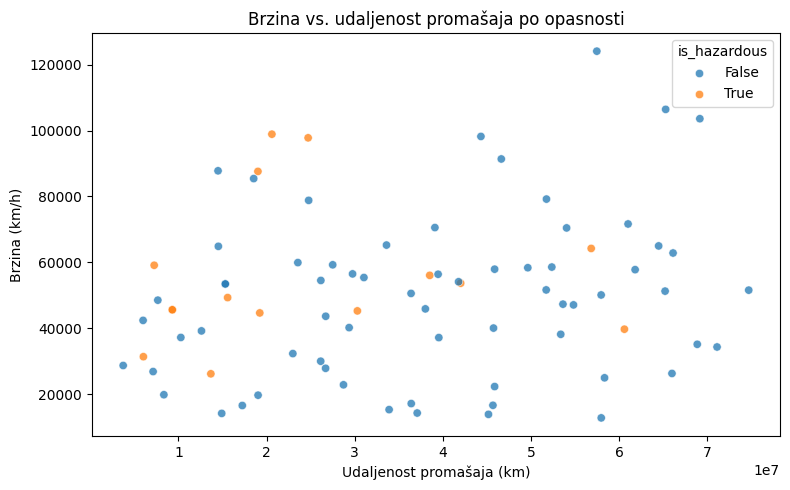

In [9]:
# 1. Osnovne informacije o tabeli i praznim poljima
print("Tipovi podataka i broj ne-praznih vrednosti:")
print(df.info())

print("\nBroj praznih (NaN) vrednosti po kolonama:")
print(df.isnull().sum())

# 2. Koliko ima opasnih (True) i neopasnih (False) asteroida
print("\nDistribucija klasa (is_hazardous):")
print(df["is_hazardous"].value_counts())
print("\nProcenat po klasama:")
print(df["is_hazardous"].value_counts(normalize=True) * 100)

# 3. Osnovna statistika brojčanih kolona
num_cols = [
    "min_diameter_km",
    "max_diameter_km",
    "velocity_km_h",
    "miss_distance_km",
]
print("\nOsnovna statistika:")
print(df[num_cols].describe())

# 4. Grafik: Brzina vs Udaljenost promašaja, obojeno po opasnosti
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="miss_distance_km",
    y="velocity_km_h",
    hue="is_hazardous",
    alpha=0.75,
)
plt.title("Brzina vs. udaljenost promašaja po opasnosti")
plt.xlabel("Udaljenost promašaja (km)")
plt.ylabel("Brzina (km/h)")
plt.tight_layout()
plt.show()

In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

# 1. Ulazne kolone (X) i ciljna kolona (y)
features = [
    "min_diameter_km",
    "max_diameter_km",
    "velocity_km_h",
    "miss_distance_km",
]
X = df[features]
y = df["is_hazardous"].astype(int)  # pretvaramo True/False u 1/0

# 2. Podela na trening (80%) i test (20%) skup
# stratify=y čuva isti odnos 1 i 0 u oba skupa
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Kreiranje i treniranje modela
model = RandomForestClassifier(
    n_estimators=100, class_weight="balanced", random_state=42
)
model.fit(X_train, y_train)

# 4. Predviđanje na test skupu
y_pred = model.predict(X_test)

# 5. Evaluacija
print("Matrica zabune (Confusion Matrix):")
print(confusion_matrix(y_test, y_pred))

print("\nIzveštaj klasifikacije (Classification Report):")
print(
    classification_report(
        y_test, y_pred, target_names=["Not Hazardous (0)", "Hazardous (1)"]
    )
)

# 6. Koje kolone su model najviše uticale na odluku
importances = pd.Series(model.feature_importances_, index=features).sort_values(
    ascending=False
)
print("\nVažnost osobina (Feature Importance):")
print(importances)

Matrica zabune (Confusion Matrix):
[[12  2]
 [ 0  3]]

Izveštaj klasifikacije (Classification Report):
                   precision    recall  f1-score   support

Not Hazardous (0)       1.00      0.86      0.92        14
    Hazardous (1)       0.60      1.00      0.75         3

         accuracy                           0.88        17
        macro avg       0.80      0.93      0.84        17
     weighted avg       0.93      0.88      0.89        17


Važnost osobina (Feature Importance):
min_diameter_km     0.397541
max_diameter_km     0.381835
miss_distance_km    0.120717
velocity_km_h       0.099908
dtype: float64
